# 线性最小二乘的数学原理

In [1]:
from pathlib import Path
import sys
root = Path.cwd().resolve()
while not (root / 'lsq').is_dir():
    if root == root.parent:
        raise RuntimeError('Run inside the repository')
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
from lsq import (finite_difference, whiten, gauss_newton,
                 levenberg_marquardt, dogleg, recursive_update)
np.set_printoptions(precision=5, suppress=True)
plt.rcParams.update({'figure.figsize': (6.4, 3.3), 'font.size': 10,
                     'axes.grid': True, 'savefig.dpi': 130})

第01章只调起点和速度。假如以后要调三个、十个数，还要每次重写一套求解公式吗？我们需要一种把“每个参数怎样影响每次读数”整齐记下来的办法，这就是矩阵在这里的用途。

**矩阵先当作一张计算表，不必先想成抽象对象。**直线 $a+bt$ 在 $t=0,1,2$ 的预测，可以写成

$$\begin{bmatrix}1&0\\1&1\\1&2\end{bmatrix}
\begin{bmatrix}a\\b\end{bmatrix}
=\begin{bmatrix}a\\a+b\\a+2b\end{bmatrix}.$$

左边的表叫 $A$，待调的两数叫 $x$。**每行对应一次观测，每列对应一个参数的作用。**$Ax$ 是让计算表按这些参数算出所有预测；代码里的 `A @ x` 做的就是这件事。

## 为什么会出现“投影”这个词

先把问题缩到只有两次观测、一个参数。假如模型只能给出 $(x,2x)$，那么可选预测是 $(0,0)$、$(1,2)$、$(2,4)$……都在同一条线上。实际读数却是 $(2,0.5)$，没有哪个 $x$ 能同时完全满足两次读数。

我们要在线上挑一个离实际读数最近的点。把读数向这条线“垂直落下去”，落脚点就是最小二乘预测。这叫**正交投影**：正交就是垂直，投影就是在允许的位置里找最近点。这里距离的平方，恰好是两次残差的平方和。

下面图中，蓝箭头是真实读数，橙箭头是选出的预测，灰线是模型能到的位置，虚线连接两者。先看虚线是否垂直灰线，再看打印的 `orthogonality` 是否接近零。它是在用数字检查垂直关系。

## 想知道公式怎么来：最低点的条件

对一般计算表 $A\in\mathbb R^{m\times n}$，即 $m$ 行、$n$ 列，评分是

$$F(x)=\frac12(Ax-y)^T(Ax-y),\qquad \nabla F(x)=A^T(Ax-y).$$

$T$ 表示转置，也就是把表的行列交换；$\nabla F$ 叫梯度，是“各个参数稍调一点，分数分别怎样变”的清单。最低点满足

$$A^TAx=A^Ty.$$

这叫**正规方程**，“正规”只是历史名称，不是说别的方法不正规。如果每列都提供其他列不能替代的信息，称为“满列秩”，参数解唯一；如果有重复或可替代的列，称为“秩亏”，不同参数可能给出同样预测。

实际计算先用 `lstsq`、QR 或 SVD。不要因为纸上能写逆矩阵，就在程序中直接算 $(A^TA)^{-1}$；第04章会看到这样做可能损失精度。

coefficient: 0.6 orthogonality: 0.0


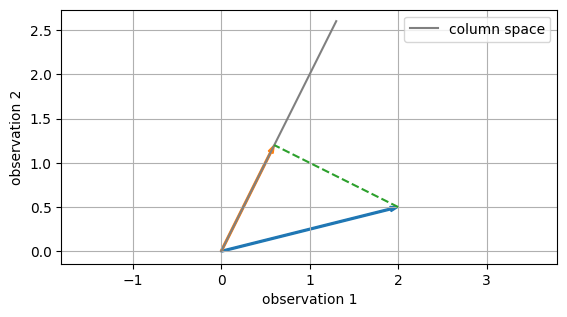

In [2]:
v = np.array([1., 2.]); y = np.array([2., .5])
x = (v@y)/(v@v)
projected = x*v
print('coefficient:', x, 'orthogonality:', v@(projected-y))
assert np.isclose(v@(projected-y), 0.)
plt.plot([0, 1.3], [0, 2.6], color='gray', label='column space')
plt.arrow(0, 0, *y, width=.02, color='C0', length_includes_head=True)
plt.arrow(0, 0, *projected, width=.02, color='C1', length_includes_head=True)
plt.plot([y[0], projected[0]], [y[1], projected[1]], '--', color='C2')
plt.axis('equal'); plt.xlabel('observation 1'); plt.ylabel('observation 2')
plt.legend(); plt.show()

## 刚才的图，横纵轴到底是什么

两根轴不是两个参数，而是**第一次、第二次观测的预测值**。我们只有一个旋钮 $x$，却要照顾两次读数，所以模型能到的地方只是一条线。把所有允许预测的位置合起来，数学上叫 $A$ 的**列空间**。你可以把它理解成“现有模型的活动范围”。

再看第01章的直线拟合。每个参数都带来一种可调的变化：截距把所有预测一起抬高；斜率让它们按时间不同程度地增加。最优残差与这两种变化都垂直，写成 $A^Tr=0$。意思是：已经没有一个很小的参数调整能继续降低平方分数。

下面回到六次观测的直线拟合。先看 `A.T @ r` 的两个数是否都接近零，不必先弄懂 `qr` 内部怎样工作。`H @ y` 是把实际读数换成允许范围内最近预测的操作；公式为

$$H=A(A^TA)^{-1}A^T,\qquad H^T=H,\quad H^2=H.$$

这段公式只适用于满列秩。$H^2=H$ 说的是：已经落在线上的点，再投一次仍在原地。代码用 `Q @ Q.T` 实现同一个操作，避免显式求逆。

In [3]:
t = np.arange(6., dtype=float)
A = np.column_stack([np.ones_like(t), t])
y = np.array([1., 2.8, 5.2, 7.1, 8.9, 11.2])
Q, R = np.linalg.qr(A, mode='reduced')
x = np.linalg.solve(R, Q.T@y)
H = Q@Q.T
r = A@x-y
print('parameters:', x, 'A.T @ r:', A.T@r)
print('training residual norm:', np.linalg.norm(r))
assert np.allclose(A.T@r, 0., atol=1e-12)
assert np.allclose(H@H, H)
assert np.allclose(H@y, A@x)

parameters: [0.94762 2.03429] A.T @ r: [0. 0.]
training residual norm: 0.33580039422535635


## 为什么继续加参数，总能把训练分数压低

把原来的模型保留，再给它一个新旋钮，至少还可以把新旋钮设为零、沿用旧预测。因此，**在不另加惩罚的普通最小二乘中，增加模型选择不会让最低训练误差变大**。但这不保证新数据上更好；第06章会看它怎样过拟合。

想看严格理由时，用这个误差分解：

$$\|Ax-y\|^2=\|Ax^*-y\|^2+\|A(x-x^*)\|^2.$$

$x^*$ 是已找到的最优参数。右边第一项是最低分，第二项是换参数后额外付出的平方距离，不能小于零。它来自两个互相垂直的方向，和直角三角形的勾股定理是同一种关系。

如果存在非零 $z$ 却有 $Az=0$，沿这个方向换参数不会改变任何预测。于是 $x^*$ 和 $x^*+z$ 一样好。**预测能确定，不等于每个参数都能分别确定。**

## 先猜，再试，再核对

问题一：把 `A` 的某一列复制一遍，能得到更好的拟合吗？

提示：原来能调出的预测，现在是否出现了新种类？

解答：没有。只是两个旋钮做了同一件事。训练误差不变，参数却不再唯一。

问题二：为什么直线拟合的残差相加接近零？如果去掉截距呢？

解答：截距对应一列全 1，$A^Tr=0$ 的这一项就是残差之和。去掉截距后不再有这个保证。

能把本章讲成“模型只能走到某些地方，我们在这些地方选离读数最近的点”，就已经抓住主线。矩阵公式是让同一个想法能处理更多读数和参数。